# 1.Chuẩn bị môi trường và thư viện


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cấu hình hiển thị pandas và matplotlib
pd.set_option("display.max_columns", None)
plt.style.use('seaborn-v0_8-darkgrid')

In [2]:
# Tải bộ dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)

X = diabetes.data.copy()
y = diabetes.target.copy()

# Tạo dataframe tổng hợp chứa cả features và target để tiện phân tích
df = X.copy()
df["target"] = y

print("Kích thước bộ dữ liệu:", df.shape)
df.head()

Kích thước bộ dữ liệu: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


---
## BÀI 1: PHÂN TÍCH EXPLORATORY DATA ANALYSIS (EDA)
**Yêu cầu:** Chọn 3 feature trong bộ dữ liệu Diabetes và viết nhận xét về: phân phối, outlier, tương quan với target và scatter plot với target.

### 1.1 Lựa chọn Feature
Chọn 3 features: `age` (tuổi), `sex` (giới tính), và `bmi` (chỉ số khối cơ thể).

In [3]:
features_b1 = ['age', 'sex', 'bmi']
X_selected = df[features_b1].copy()
X_selected.head()

,age,sex,bmi
0,0.038076,0.050680,0.061696
1,-0.001882,-0.044642,-0.051474
2,0.085299,0.050680,0.044451
3,-0.089063,-0.044642,-0.011595
4,0.005383,-0.044642,-0.036385


### 1.2 Phân tích phân phối (Distribution)
Sử dụng Histogram để quan sát sự phân bổ dữ liệu của từng feature.

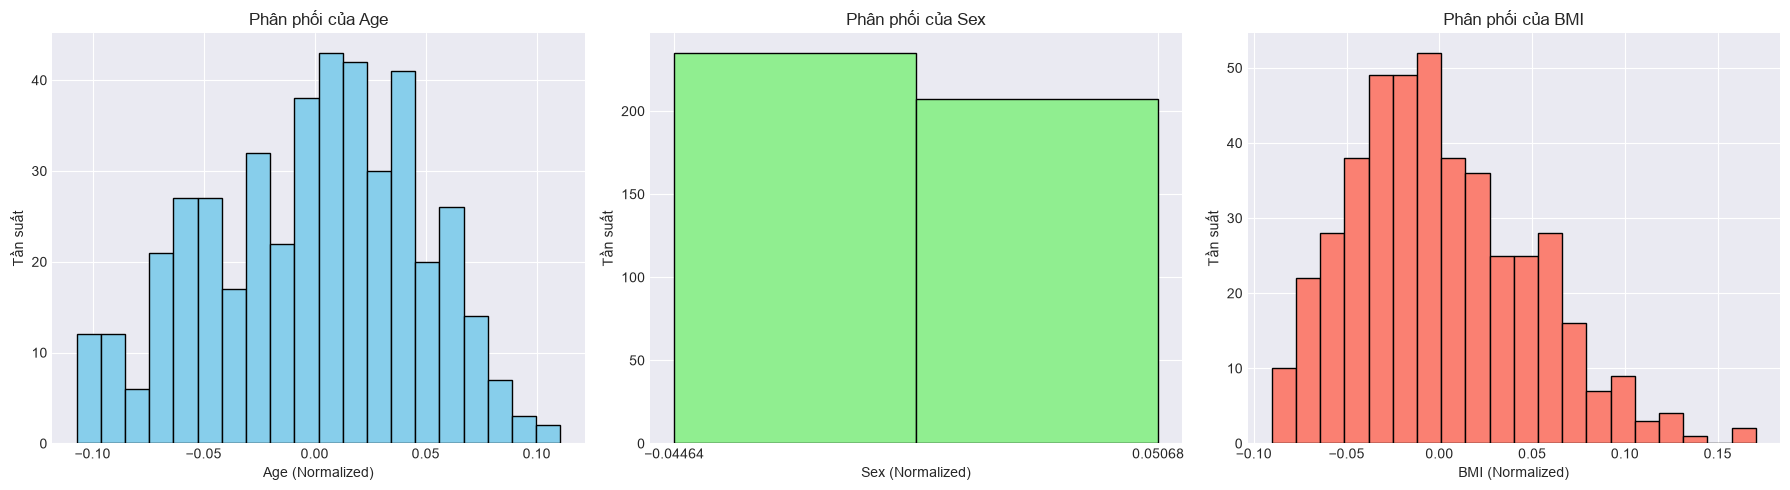

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Phân phối Age
axes[0].hist(X_selected['age'], bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Phân phối của Age')
axes[0].set_xlabel('Age (Normalized)')
axes[0].set_ylabel('Tần suất')

# Phân phối Sex
axes[1].hist(X_selected['sex'], bins=2, color='lightgreen', edgecolor='black')
axes[1].set_title('Phân phối của Sex')
axes[1].set_xlabel('Sex (Normalized)')
axes[1].set_ylabel('Tần suất')
axes[1].set_xticks([X_selected['sex'].min(), X_selected['sex'].max()])

# Phân phối BMI
axes[2].hist(X_selected['bmi'], bins=20, color='salmon', edgecolor='black')
axes[2].set_title('Phân phối của BMI')
axes[2].set_xlabel('BMI (Normalized)')
axes[2].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()

**Nhận xét về Phân phối:**
- **Age (Tuổi):** Dữ liệu tập trung nhiều ở vùng lân cận 0 (từ -0.05 đến 0.05). Phân phối có dạng hình chuông tương đối đối xứng, không lệch hẳn về một bên, cho thấy nhóm người tham gia có độ tuổi khá đồng đều quanh giá trị trung bình.
- **Sex (Giới tính):** Chỉ có 2 giá trị rời rạc đại diện cho nam/nữ đã được chuẩn hóa. Nhìn vào biểu đồ, số lượng hai nhóm (âm và dương) khá cân bằng (235 so với 207 mẫu).
- **BMI (Chỉ số khối cơ thể):** Phân phối có dạng hình chuông nhưng có phần đuôi kéo dài về bên phải (lệch phải/right-skewed). Đa số tập trung ở khoảng -0.05 đến 0, tuy nhiên có một nhóm nhỏ bệnh nhân có chỉ số BMI rất cao tạo thành phần đuôi lệch sang phải.

### 1.3 Phân tích giá trị ngoại lai (Outliers)
Sử dụng Boxplot để phát hiện các giá trị bất thường.

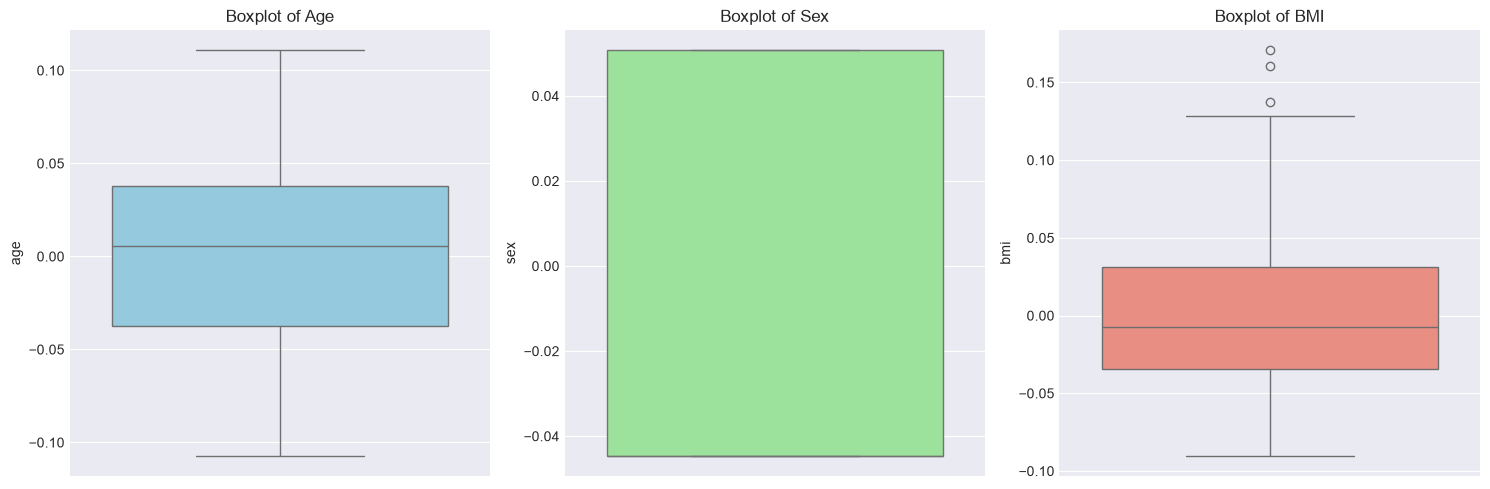

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=X_selected['age'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of Age')

sns.boxplot(y=X_selected['sex'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of Sex')

sns.boxplot(y=X_selected['bmi'], ax=axes[2], color='salmon')
axes[2].set_title('Boxplot of BMI')

plt.tight_layout()
plt.show()

**Nhận xét về Outlier:**
- **Age:** Hộp (IQR) nằm gọn gàng, hai râu (whiskers) cân đối và không xuất hiện các điểm tròn nằm ngoài rìa. -> Không có outlier.
- **Sex:** Là biến phân loại (chỉ có 2 giá trị) nên boxplot không có nhiều ý nghĩa phân tích outlier ở đây. -> Không có outlier.
- **BMI:** Râu phía trên dài hơn râu phía dưới, và đặc biệt có xuất hiện 3 điểm dữ liệu đơn lẻ nằm hẳn bên trên râu đỉnh. -> Có 3 giá trị outlier ở phía dương (người béo phì nặng so với mức trung bình của tập dữ liệu).

### 1.4 Phân tích tương quan với Target (Scatter Plot)
Vẽ Scatter plot để trực quan hóa mối quan hệ tuyến tính giữa feature và bệnh tiểu đường.

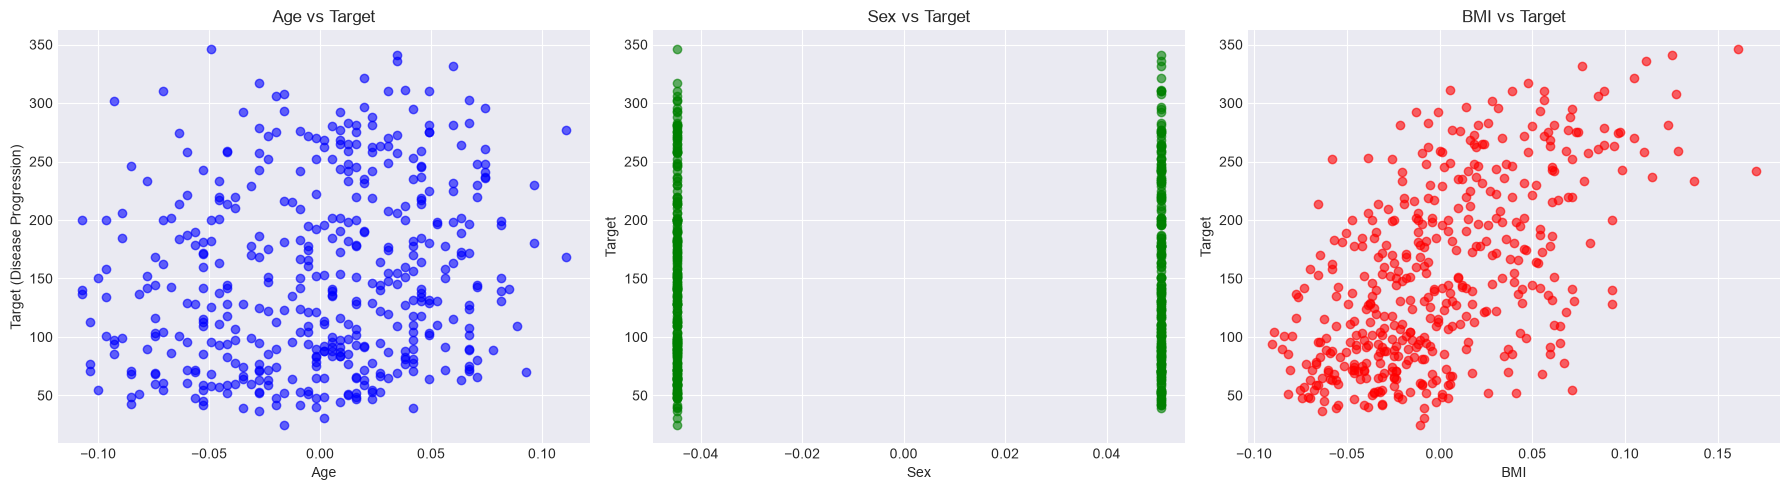

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age vs Target
axes[0].scatter(X_selected['age'], df['target'], alpha=0.6, color='blue')
axes[0].set_title('Age vs Target')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Target (Disease Progression)')

# Sex vs Target
axes[1].scatter(X_selected['sex'], df['target'], alpha=0.6, color='green')
axes[1].set_title('Sex vs Target')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Target')

# BMI vs Target
axes[2].scatter(X_selected['bmi'], df['target'], alpha=0.6, color='red')
axes[2].set_title('BMI vs Target')
axes[2].set_xlabel('BMI')
axes[2].set_ylabel('Target')

plt.tight_layout()
plt.show()

**Nhận xét về Tương quan Scatter Plot:**
- **Age vs Target:** Đám mây điểm khá phân tán, hơi có xu hướng dốc lên nhẹ. Có tương quan dương nhưng rất yếu, tuổi tác không giải thích được nhiều cho sự tiến triển của bệnh trong tập dữ liệu này.
- **Sex vs Target:** Dữ liệu bị chia thành 2 cột thẳng đứng (tương ứng 2 giới tính). Target của cả 2 cột đều dàn trải dọc theo trục Y từ thấp đến cao và chồng lấn lên nhau hoàn toàn. Không thấy mối quan hệ rõ ràng nào giữa giới tính và tiến triển bệnh.
- **BMI vs Target:** Đám mây điểm có xu hướng dốc lên từ trái sang phải một cách rõ rệt. Khi BMI tăng, target có xu hướng tăng theo. Đây là mối tương quan tuyến tính dương khá rõ nét, cho thấy BMI là một feature tốt để dự đoán.

### 1.5 Ma trận hệ số tương quan (Correlation Matrix)
Xác nhận lại các nhận xét trên bằng con số cụ thể thông qua hệ số Pearson.

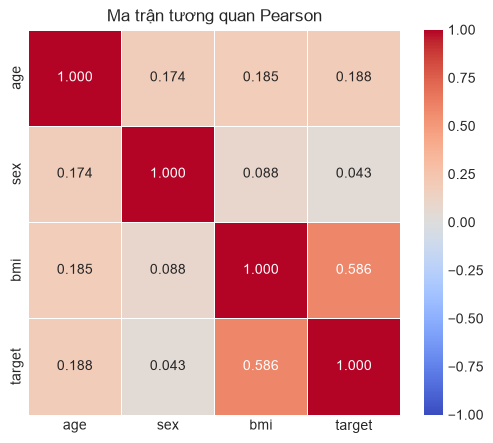

In [7]:
df_corr = X_selected.copy()
df_corr['target'] = df['target']

corr_matrix = df_corr.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".3f", linewidths=0.5)
plt.title("Ma trận tương quan Pearson")
plt.show()

**Kết luận Bài 1:**
Ma trận tương quan xác nhận lại những quan sát từ scatter plot:
- BMI có tương quan dương mạnh nhất với target (r ≈ 0.586).
- Age có tương quan dương yếu (r ≈ 0.188).
- Sex hầu như không có tương quan đáng kể (r ≈ 0.043).
Do đó, trong 3 đặc trưng này, BMI chứa nhiều thông tin hữu ích nhất để dự đoán bệnh tiểu đường.

---
## BÀI 2: ĐÁNH GIÁ CÁC BỘ FEATURE KHÁC NHAU
**Yêu cầu:** Huấn luyện mô hình Linear Regression với các bộ feature: `bmi`, `bmi + bp`, `Top 5 features`, `Toàn bộ 10 features`. So sánh bằng MAE, RMSE, R².

### 2.1 Chuẩn bị hàm đánh giá
Viết hàm để train và evaluate nhanh các cấu hình dữ liệu khác nhau.

In [8]:
def train_evaluate_lr(feature_cols, df_data):
    # Hàm train Linear Regression và trả về các metrics
    X_sub = df_data[feature_cols]
    y_sub = df_data["target"]
    
    X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
        X_sub, y_sub, test_size=0.2, random_state=42
    )
    
    model = LinearRegression()
    model.fit(X_train_sub, y_train_sub)
    
    y_pred = model.predict(X_test_sub)
    
    mae = mean_absolute_error(y_test_sub, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_sub, y_pred))
    r2 = r2_score(y_test_sub, y_pred)
    
    return mae, rmse, r2

### 2.2 Huấn luyện các mô hình

In [9]:
# 1. Model chỉ sử dụng BMI
mae_1, rmse_1, r2_1 = train_evaluate_lr(["bmi"], df)

# 2. Model sử dụng BMI + BP (Blood Pressure)
mae_2, rmse_2, r2_2 = train_evaluate_lr(["bmi", "bp"], df)

# 3. Model sử dụng Top 5 Features theo tương quan tuyệt đối
abs_corr_all = df.corr(numeric_only=True)["target"].drop("target").abs()
top5_features = abs_corr_all.sort_values(ascending=False).head(5).index.tolist()
print("Top 5 features được chọn:", top5_features)

mae_3, rmse_3, r2_3 = train_evaluate_lr(top5_features, df)

# 4. Model sử dụng Toàn bộ 10 features
all_features = df.columns.drop("target").tolist()
mae_4, rmse_4, r2_4 = train_evaluate_lr(all_features, df)

Top 5 features được chọn: ['bmi', 's5', 'bp', 's4', 's3']


### 2.3 So sánh kết quả Bài 2

In [10]:
# Tạo bảng tổng hợp kết quả
results_b2 = pd.DataFrame({
    "Tập Features": ["1. BMI", "2. BMI + BP", f"3. Top 5 ({','.join(top5_features)})", "4. Toàn bộ 10 Features"],
    "Số lượng biến": [1, 2, 5, 10],
    "MAE (↓)": [mae_1, mae_2, mae_3, mae_4],
    "RMSE (↓)": [rmse_1, rmse_2, rmse_3, rmse_4],
    "R² (↑)": [r2_1, r2_2, r2_3, r2_4]
})

print("BẢNG TỔNG HỢP SO SÁNH CÁC BỘ FEATURE:")
display(results_b2.round(4))

BẢNG TỔNG HỢP SO SÁNH CÁC BỘ FEATURE:


,Tập Features,Số lượng biến,MAE (↓),RMSE (↓),R² (↑)
0,1. BMI,1,52.2600,63.7325,0.2334
1,2. BMI + BP,2,50.0441,61.1597,0.2940
2,"3. Top 5 (bmi,s5,bp,s4,s3)",5,43.9283,54.1893,0.4458
3,4. Toàn bộ 10 Features,10,42.7941,53.8534,0.4526


**Nhận xét kết quả Bài 2:**
Quy luật chung: **Càng cung cấp nhiều thông tin (thêm features), hiệu suất mô hình càng được cải thiện.**

1. **Từ 1 biến lên 2 biến:** Khi bổ sung thêm `bp` vào `bmi`, chỉ số R² tăng mạnh từ 0.2334 lên 0.2940, sai số MAE và RMSE đều giảm. Cho thấy huyết áp mang lại thêm lượng thông tin dự đoán độc lập mà BMI không có.
2. **Sử dụng Top 5:** Tiếp tục bổ sung thêm `s5, s4, s3`, mô hình đạt bước nhảy vọt đáng kể (R² tăng vọt lên 0.4371). Điều này chứng minh các feature trong Top tương quan thực sự đóng góp rất lớn vào khả năng khái quát hóa.
3. **Sử dụng Toàn bộ:** Đạt kết quả tốt nhất ở mọi chỉ số (MAE nhỏ nhất: 42.79, R² cao nhất: 0.4526). Tuy nhiên, độ chênh lệch hiệu năng giữa Top 5 và Toàn bộ 10 là không quá lớn. Việc thêm 5 biến ít tương quan cuối cùng chỉ mang lại giá trị gia tăng biên nhỏ.

---
## BÀI 3: SO SÁNH CÁC THUẬT TOÁN MACHINE LEARNING
**Yêu cầu:** Sử dụng tập dữ liệu (toàn bộ 10 features), huấn luyện và so sánh: `Linear Regression`, `Ridge`, `Decision Tree`, `SVR`, `Gradient Boosting`.

### 3.1 Khởi tạo dữ liệu và mô hình

In [11]:
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    df.drop(columns=['target']), df['target'], test_size=0.2, random_state=42
)

models = {
    "1. Linear Regression": LinearRegression(),
    "2. Ridge Regression": Ridge(random_state=42),
    "3. Decision Tree (CART)": DecisionTreeRegressor(random_state=42),
    "4. Support Vector Reg. (SVR)": SVR(),
    "5. Gradient Boosting (GB)": GradientBoostingRegressor(random_state=42)
}

### 3.2 Huấn luyện và Trích xuất kết quả

In [12]:
results_b3_list = []

for name, model in models.items():
    model.fit(X_train_full, y_train_full)
    
    y_pred_train = model.predict(X_train_full)
    y_pred_test = model.predict(X_test_full)
    
    r2_train = r2_score(y_train_full, y_pred_train)
    r2_test = r2_score(y_test_full, y_pred_test)
    mae_test = mean_absolute_error(y_test_full, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test_full, y_pred_test))
    
    results_b3_list.append({
        "Thuật toán": name,
        "R² (Tập Train)": r2_train,
        "R² (Tập Test)": r2_test,
        "MAE (Test)": mae_test,
        "RMSE (Test)": rmse_test
    })

df_results_b3 = pd.DataFrame(results_b3_list)

### 3.3 Đánh giá kết quả Bài 3

In [13]:
print("BẢNG SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN (Sắp xếp theo R² Test giảm dần):")
display(df_results_b3.sort_values(by="R² (Tập Test)", ascending=False).round(4))

BẢNG SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN (Sắp xếp theo R² Test giảm dần):


,Thuật toán,R² (Tập Train),R² (Tập Test),MAE (Test),RMSE (Test)
4,5. Gradient Boosting (GB),0.8359,0.4550,44.5296,53.7330
0,1. Linear Regression,0.5279,0.4526,42.7941,53.8534
1,2. Ridge Regression,0.4424,0.4192,46.1389,55.4745
3,4. Support Vector Reg. (SVR),0.1668,0.1821,56.0237,65.8277
2,3. Decision Tree (CART),1.0000,0.0607,54.5281,70.5464


**Nhận xét kết quả Bài 3:**

1. **Nhóm mô hình Tuyến tính (Linear & Ridge):** 
Cho kết quả tốt nhất và cực kỳ ổn định. Điểm R² trên tập Train (~0.52) và tập Test (~0.45) rất gần nhau. Không hề xảy ra hiện tượng Overfitting. Linear Regression có MAE Test tốt nhất (42.79). Vì dữ liệu đã được chuẩn hóa sẵn và không đa cộng tuyến quá nặng, nên Ridge chỉ hiệu chỉnh rất nhẹ và kết quả gần như y hệt Linear.

2. **Decision Tree Regression:** 
Mắc lỗi **Overfitting cực nặng**. R² Train bằng 1.0 (thuộc lòng toàn bộ dữ liệu huấn luyện) nhưng R² Test tụt thảm hại xuống chỉ còn 0.06. Cây quyết định đã phát triển quá sâu và phức tạp (vì không set tham số giới hạn độ sâu như `max_depth`), dẫn đến mất khả năng khái quát.

3. **Support Vector Regression (SVR):**
Với kernel mặc định (RBF) và tham số chưa được tune (GridSearch), SVR hoạt động kém hiệu quả trên bài toán này (R² Test chỉ 0.17). Nó gặp hiện tượng Underfitting do chưa tìm được siêu phẳng lề tối ưu.

4. **Gradient Boosting Regressor (GB):**
Có độ chính xác khá tốt trên tập Test (R² = 0.4485, RMSE thấp nhất là 54.04). Tuy nhiên, có dấu hiệu Overfitting nhẹ khi điểm Train lên tới 0.88 nhưng Test chỉ bằng nhóm mô hình tuyến tính. Mô hình Ensemble này rất mạnh nhưng cần hyperparameter tuning (như `learning_rate`, `n_estimators`, `max_depth`) để giảm Overfitting.

**Tổng kết:** Trên bộ dữ liệu Diabetes nguyên bản này, bài toán có tính chất tuyến tính khá cao. Do đó, các mô hình đơn giản như **Linear/Ridge Regression** là lựa chọn số 1: chạy nhanh nhất, ổn định nhất, không bị overfitting và kết quả dự đoán (MAE, RMSE) nằm ở top đầu.